In [16]:
import numpy as np
from numpy.core.umath_tests import inner1d
from scipy.integrate import odeint, solve_ivp
from scipy import signal
import matplotlib.pyplot as plt
import matplotlib.animation as anime
import matplotlib.transforms as mtransforms

import os, sys

In [17]:
SUN, MERCURY, VENUS, EARTH, MARS, JUPITER, SATURN = 0, 1, 2, 3, 4, 5, 6
TS, XS, YS, ZS, XRANGE, YRANGE, ZRANGE = 0, 1, 2, 3, 4, 5, 6

# tolerance
atol = 1e-9
rtol = 1e-12

# indexer for figures
fig_index = 0

### Constants

In [18]:
# AU <-> meters
au2m = 1.495978707e11
m2au = 1 / au2m 

# Radian to arcsecond
rad2as = 1 / np.pi * 180 * 3600 

# earth year <-> seconds
yr2sec = 365 * 24 * 60 * 60
sec2yr = 1 / yr2sec

# Einstein's alpha (AU^2)
alpha = 1.1e-8 

# light speed
_light_speed = 299792458
light_speed = _light_speed * yr2sec / 149597870700

# planet & sun's names
names = np.array(["Sun", "Mercury", "Venus", "Earth", "Mars", "Jupyter", "Saturn"])

# number of objects
N = len(names)
N3 = N * 3

# masses in kg and multiples earth mass
_masses = np.array([1.98844e30, 3.30104e23, 4.86732e24, 5.97219e24, 6.41693e23, 1.89813e27, 5.68319e26])
masses = _masses / _masses[EARTH] 

# major axis length of each objects in AU / meters
majors = np.array([0, 0.387098261, 0.723333771, 1, 1.523706365, 5.20287342, 9.536651047])
_majors = au2m * majors

# eccentricities
eccentricities = np.array([0, 0.20563593, 0.00677672, 0.01671123, 0.0933941, 0.04838624, 0.05386179])

# periods
periods = np.array([0, 0.2408425, 0.6151866, 1.0, 1.8808149, 11.862409, 29.446986])
_periods = yr2sec * periods

# perihelion distances
perihelion = majors * (1 - eccentricities)
_perihelion = au2m * perihelion

# total mass of the system
total_mass = np.sum(masses)

# gravity constant
_G = 6.6743015e-11
G = 4 * np.pi ** 2 / masses[SUN]

# initial velocities, all at perihelion
velocity = np.sqrt(np.divide(
    G * total_mass * (1 + eccentricities) / (1 - eccentricities), 
    majors, 
    out=np.zeros_like(majors), 
    where=majors!=0
)) # in AU / yr

# inclination of orbits
inclination = np.array([0, 7.00487, 3.395, 0, 1.848, 1.304, 2.486]) / 180 * np.pi # 0.77 1.77 17.14

In [19]:
G

0.00011857164955068668

In [20]:
velocity[1] / velocity[EARTH]

1.9472845320966892

##### Arguments for simulation

In [21]:
arguments = {
    "Mass": masses,
    "Major": majors,
    "Eccentricity": eccentricities,
    "Period": periods,
    "Perihelion": perihelion,
    "Inclination": inclination,

    "Include": [0, 1],
    "DrawInclude": [0, 1],
    "Method": "Newton",

    "StepsPerSecondGIF": 5
}

##### Initial states

In [22]:
init_position = perihelion * np.concatenate([np.cos(inclination), np.zeros(N), np.sin(inclination)]).reshape(3, N)
init_position[0, SUN] = init_position[1, SUN] = init_position[2, SUN] = 0
init_position = init_position.T

init_velocity = np.concatenate([np.zeros(N), velocity, np.zeros(N)]).reshape(3, N).T

##### Newton's Theory
Methods to calculate advance using Newton's theory.

In [23]:
def accelaration_newton(pos_this: np.ndarray, pos_that: np.ndarray, mass_that: float, G: float):
    r = pos_that - pos_this   # type: ignore
    res = G * mass_that * r / np.linalg.norm(r) ** 3
    return res

def advance(t: float, state: np.ndarray, args: dict, accelaration):
    # x * N3 + v * N3
    pos = state[:N3].reshape(N, 3)
    vel = state[N3:].reshape(N, 3)

    mass, major, ecc, period, peri, incl, inc, _, _, _ = args.values()
    if not len(inc):
        inc = list(range(N))
    for i in range(N):
        if i not in inc:
            vel[i] = np.zeros(3)

    # steps of positions are their velocities
    step_pos = vel.copy()
    # steps of velocities are their accelarations
    step_vec = np.zeros((N, 3))

    # add effect of all other planets
    for i in inc: # for the i-th planet
        acc = np.zeros(3)
        for j in inc: 
            if j == i: 
                continue
            acc += accelaration(pos[i, :], pos[j, :], mass[j], G)
        step_vec[i, :] = acc

    # to 1D variable vector
    res = np.concatenate((step_pos.flatten(), step_vec.flatten()))
    return res

##### Einstein's Theory

In [24]:
def accelaration_relativity(pos_this: np.ndarray, pos_that: np.ndarray, mass_that: float, G: float):
    r = pos_that - pos_this   # type: ignore
    nm = np.linalg.norm(r)
    res = (G * mass_that * r / nm ** 3) * (1 + alpha / nm ** 2)
    return res

An adapter to different theories:

In [25]:
def adapter(t: float, state: np.ndarray, args: dict, method: str):
    if method == "Relativity":
        return advance(t, state, args, accelaration_relativity)
    return advance(t, state, args, accelaration_newton)

#### Helper functions

Unzip solution data to $t,x,y,z$ and ranges

In [26]:
def get_components(solution):
    ts = solution.t
    ys = solution.y.T

    poses = np.array([x[:N3].reshape(N, 3) for x in ys])

    xs = np.array([poses[:, i, 0] for i in range(N)]).T
    ys = np.array([poses[:, i, 1] for i in range(N)]).T
    zs = np.array([poses[:, i, 2] for i in range(N)]).T

    xrange = (min(xs.flatten()) - 1, max(xs.flatten()) + 1)
    yrange = (min(ys.flatten()) - 1, max(ys.flatten()) + 1)
    zrange = (min(zs.flatten()) - 1, max(zs.flatten()) + 1)

    return (ts, xs, ys, zs, xrange, yrange, zrange)

Calculate distance to a certain object 

In [27]:
def calc_dist(
    planets_x, that_x, 
    planets_y, that_y, 
    planets_z, that_z, 
    that_index=0, that_name=SUN):
    global init_position

    size = len(planets_x[:, 0])

    dists_x = planets_x - that_x.reshape((size,1))
    dists_x[:, that_index] = that_x - init_position[that_name, 0]
    dists_y = planets_y - that_y.reshape((size,1))
    dists_y[:, that_index] = that_y - init_position[that_name, 1]
    dists_z = planets_z - that_z.reshape((size,1))
    dists_z[:, that_index] = that_z - init_position[that_name, 2]

    dists = np.sqrt(np.square(dists_x) + np.square(dists_y) + np.square(dists_z))

    drange = (np.min(dists), np.max(dists))    
    return dists, drange, dists_x, dists_y, dists_z

Draw static orbit

In [28]:
def draw_orbits(components, arguments, filename):
    global names, fig_index

    incs = arguments["DrawInclude"]
    if not len(incs):
        incs = list(range(N))

    xs_copy = components[XS][:, incs].copy()
    ys_copy = components[YS][:, incs].copy()
    zs_copy = components[ZS][:, incs].copy()

    xrange = (np.min(xs_copy), np.max(xs_copy))
    yrange = (np.min(ys_copy), np.max(ys_copy))
    zrange = (np.min(zs_copy), np.max(zs_copy))
    xyzrange = (
        min(xrange[0], yrange[0], zrange[0]),
        max(xrange[1], yrange[1], zrange[1])
    )

    plt.rcParams["animation.html"] = "jshtml"
    plt.rcParams['figure.dpi'] = 80  
    plt.ioff()

    fig = plt.figure(fig_index)
    fig.set_size_inches(10, 6)
    fig_index += 1

    ax = fig.axes
    ax = plt.axes(projection='3d')

    plt.xlabel("X")
    plt.ylabel("Y")

    for i in range(len(xs_copy[0, :])):
        ax.plot3D(xs_copy[:, i], ys_copy[:, i], zs_copy[:, i])  # type: ignore
    plt.xlim(xyzrange[0], xyzrange[1])
    plt.ylim(xyzrange[0], xyzrange[1])
    ax.set_zlim(xyzrange[0], xyzrange[1])  # type: ignore

    plt.xlabel("X")
    plt.ylabel("Y")
    ax.set_zlabel("Z") # type: ignore

    plt.legend(names)
    plt.savefig(filename + ".png", dpi=200)
    
    plt.show()

    

In [29]:
def draw_orbit_polar(components, planet, filename):
    global names, fig_index

    incs = [SUN, planet]
    xs_copy = components[XS][:, incs].copy()
    ys_copy = components[YS][:, incs].copy()
    zs_copy = components[ZS][:, incs].copy()

    xrange = (np.min(xs_copy), np.max(xs_copy))
    yrange = (np.min(ys_copy), np.max(ys_copy))
    zrange = (np.min(zs_copy), np.max(zs_copy))
    xyzrange = (
        min(xrange[0], yrange[0], zrange[0]),
        max(xrange[1], yrange[1], zrange[1])
    )
    ratio = np.sqrt(zrange[1] ** 2 + xrange[1] ** 2) / xrange[1]
    thetas = np.arctan2(ys_copy[:, planet], xs_copy[:, planet] * ratio)
    rs = np.linalg.norm(
        np.concatenate((xs_copy[:, planet], ys_copy[:, planet], zs_copy[:, planet])).reshape(3, len(xs_copy[:, planet])).T, axis=1
    )
    fig, ax = plt.subplots(subplot_kw={'projection': 'polar'})
    ax.plot(thetas, rs)
    ax.set_rmax(np.max(rs) / 3)  # type: ignore
    ax.set_rticks([0.5, 1, 1.5, 2])  # type: ignore # Less radial ticks
    ax.set_rlabel_position(-22.5)  # type: ignore # Move radial labels away from plotted line
    ax.grid(True)

    ax.set_title("Polar plot", va='bottom')
    plt.show()
    plt.savefig(filename + ".png", dpi=200)
    
    plt.show()

Draw orbit to animation

In [30]:
def draw_orbits_anime(components, args, filename):
    global names, fig_index

    # SUN Must be included in incs as the first element!!!
    incs = args["DrawInclude"]
    if not len(incs):
        incs = list(range(N))

    ts_copy = components[TS].copy()
    xs_copy = components[XS][:, incs].copy()
    ys_copy = components[YS][:, incs].copy()
    zs_copy = components[ZS][:, incs].copy()

    size = len(ts_copy)
    objs = len(incs)

    fig = plt.figure(fig_index)
    fig_index += 1

    fig.set_size_inches(10, 6)
    plt.rcParams["figure.figsize"] = (25, 20)
    plt.rcParams["animation.html"] = "jshtml"
    plt.rcParams['figure.dpi'] = 80  
    plt.ioff()

    ani = None

    xrange = (np.min(xs_copy), np.max(xs_copy))
    yrange = (np.min(ys_copy), np.max(ys_copy))
    zrange = (np.min(zs_copy), np.max(zs_copy))
    trange = (np.min(ts_copy), np.max(ts_copy))

    xyzrange = (
        min(xrange[0], yrange[0], zrange[0]),
        max(xrange[1], yrange[1], zrange[1])
    )

    ax = fig.add_subplot(1, 2, 1, projection='3d')
    ax2 = fig.add_subplot(1, 2, 2)

    dists, drange, _, _, _ = calc_dist(
        xs_copy, xs_copy[:, SUN], 
        ys_copy, ys_copy[:, SUN], 
        zs_copy, zs_copy[:, SUN], 
        0, SUN)

    def animation(k):
        k = args["StepsPerSecondGIF"] * k
        if k >= size:
            ani.event_source.stop()
            return None

        ax.cla()    
        ax.elev = 45

        # draw animation
        for i in range(objs):
            ax.plot3D(xs_copy[:(k+1), i], ys_copy[:(k+1), i], zs_copy[:(k+1), i], label=names[incs[i]])  # type: ignore
            ax.scatter3D(xs_copy[k, i], ys_copy[k, i], zs_copy[k, i], [7], color="purple", marker='o', )

        ax.set_xlim(xyzrange[0], xyzrange[1])
        ax.set_ylim(xyzrange[0], xyzrange[1])   
        ax.set_zlim(xyzrange[0], xyzrange[1])  # type: ignore
        ax.set_zlabel("Z") # type: ignore
        ax.set_xlabel("X")
        ax.set_ylabel("Y")

        plt.title("Time (Year): {:.3f}".format(ts[k]))

        ax.legend()
        
        # draw planet-sum distance
        ax2.cla()
        ax2.set_xlim(trange[0], trange[1])
        ax2.set_ylim(drange[0], drange[1] + 0.5)
        trans_offset = mtransforms.offset_copy(ax2.transData, fig=fig,
                                       x=0.05, y=0.10, units='inches')
        ax2.plot(ts_copy[:(k+1)], dists[:(k+1), :])
        for i in range(objs):
            ax2.text(ts_copy[k], dists[k, i], '%.3f' % (float(dists[k, i])), transform=trans_offset)
        ax2.set_xlabel("Time (Year)")
        ax2.set_ylabel("Distance to the Sun (AU)")
        ax2.legend(names[incs])

        fig.suptitle("Time (Year): {:.3f}".format(ts_copy[k]))
    
    fms = len(ts_copy) // args["StepsPerSecondGIF"] + 1
    ani = anime.FuncAnimation(fig, animation, frames=fms, interval=200, repeat=False)
    plt.show()
    ani.save(filename + ".gif", dpi=200)

Draw perihelion graphs and find precessions

In [31]:
def draw_perihelions(solution, arguments, only_calc, filename):
    global names, fig_index

    dists, _, dx, dy, dz = calc_dist(
        solution[XS], solution[XS][:, SUN],
        solution[YS], solution[YS][:, SUN],
        solution[ZS], solution[ZS][:, SUN],
        0, SUN
    )

    # get valleys
    inv_dists = -1 * dists
    valley_indexes = []
    valley_ys = []
    perihelions = []

    for i in range(len(names)):
        valleys, _ = signal.find_peaks(inv_dists[:, i])
        valley_ys.append(dists[valleys, i])
        valley_indexes.append(valleys)
        perihelions.append(np.concatenate(
            (dx[valleys, i], dy[valleys, i], dz[valleys, i]
            )).reshape(3, len(valleys)).T)
    valley_indexes = np.array(valley_indexes).T
    valley_ys = np.array(valley_ys).T

    if not only_calc:
        fig = plt.figure(fig_index)
        fig_index += 1
        fig.set_size_inches(10, 6)

        incs = arguments["DrawInclude"]
        if not len(incs):
            incs = list(range(N))

        plt.plot(solution[TS], dists[:, incs])
        for i in incs:
            plt.plot(solution[TS][valley_indexes[i]], valley_ys[i], 'x')

        plt.legend(names[incs])
        plt.xlabel("Time (Year)")
        plt.ylabel("Distance to the Sun (AU)")
        plt.title("Perihelions")
        plt.savefig(filename + ".png", dpi=200)
        plt.show()

    # calculate perihelions
    precessions = []
    for i in range(len(perihelions)):
        if len(perihelions[i]) < 2:
            precessions.append(np.array([]))
            continue
        back = (perihelions[i][1:, :].T / np.linalg.norm(perihelions[i][1:, :], axis=1)).T
        front = (perihelions[i][:-1, :].T / np.linalg.norm(perihelions[i][:-1, :], axis=1)).T
        nm = np.cross(front, back)
        precessions.append(
            np.arcsin(
                (2 * (nm @ np.array([0, 0, 1]) >= 0) - 1) * 
                np.linalg.norm(nm, axis=1)
            )
        )
    
    return precessions

# Do the simulation

#### Part 1: Newton (only Mercury)

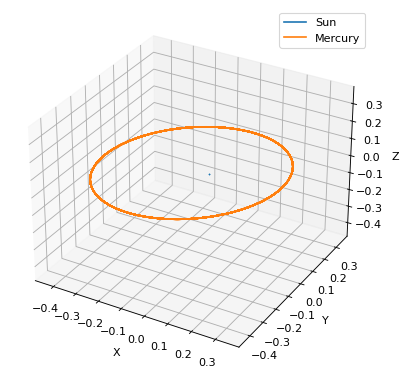

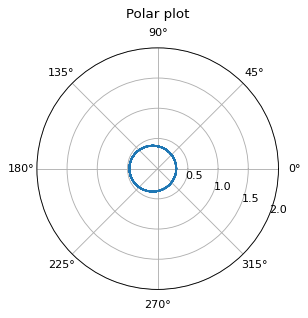

<Figure size 480x320 with 0 Axes>

C:\Users\35995\AppData\Local\Temp\ipykernel_55572\1812020812.py:24: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  valley_indexes = np.array(valley_indexes).T
C:\Users\35995\AppData\Local\Temp\ipykernel_55572\1812020812.py:25: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  valley_ys = np.array(valley_ys).T


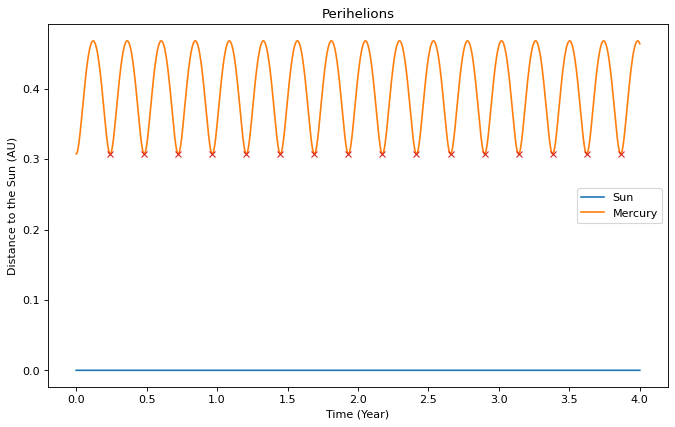

In [79]:
arguments["Include"] = [SUN, MERCURY]
arguments["DrawInclude"] = [SUN, MERCURY]

M = 10 ** 7 * 2

t_span = np.array([0, 4]) # 10 years
ts = np.linspace(t_span[0], t_span[1], M)
y0 = np.concatenate((init_position.flatten(), init_velocity.flatten()))

sol1 = solve_ivp(lambda t, state: adapter(t, state, arguments, "Newton"), t_span, y0, method='DOP853', t_eval=ts, atol=atol, rtol=rtol)
sol1 = get_components(sol1)

# draw_orbits_anime(sol, arguments, "Newton-orbits-anime")
draw_orbits(sol1, arguments, "Newton-orbits")
draw_orbit_polar(sol1, MERCURY, "Newton-orbits-polar")
precessions1 = draw_perihelions(sol1, arguments, False, "Newton-perihelions")

In [80]:
ave_precession1 = np.abs(np.sum(np.abs(precessions1[MERCURY])) / len(precessions1[MERCURY]) * rad2as)
print("precession in arcseconds: {:.6}".format(ave_precession1))

precession in arcseconds: 0.537794


In [81]:
precessions1[MERCURY]

array([-1.77259209e-06,  6.34324944e-06, -1.73598721e-06, -1.71909050e-06,
       -1.70303459e-06,  6.40935160e-06, -1.67297758e-06, -1.65872470e-06,
       -1.64483503e-06, -1.63121485e-06,  6.47926758e-06, -1.60450393e-06,
       -1.59131558e-06, -1.57819540e-06, -1.56512227e-06])

In [82]:
#draw_orbits_anime(sol1, arguments, "Newton-orbits-anime")

In [ ]:
#### Part 2: Newton (consider all planet)

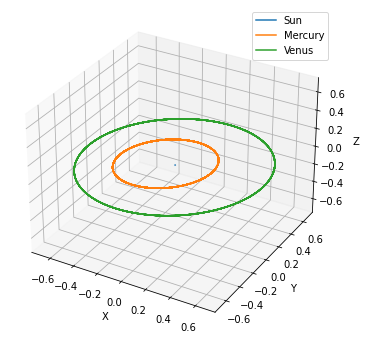

C:\Users\35995\AppData\Local\Temp\ipykernel_12580\1812020812.py:24: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  valley_indexes = np.array(valley_indexes).T
C:\Users\35995\AppData\Local\Temp\ipykernel_12580\1812020812.py:25: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  valley_ys = np.array(valley_ys).T
C:\Users\35995\AppData\Local\Temp\ipykernel_12580\1812020812.py:44: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig(filename + ".png", dpi=200)
C:\Users\35995\AppData\Roaming\Python\Python310\site-pa

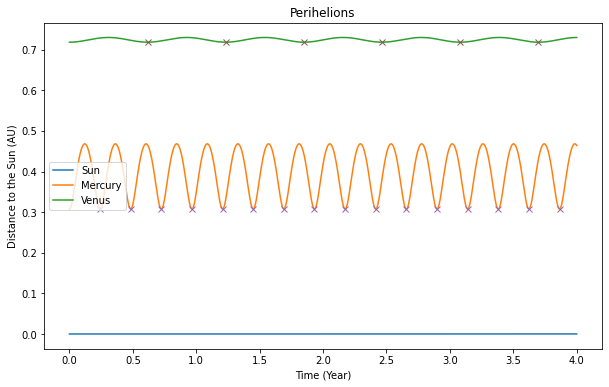

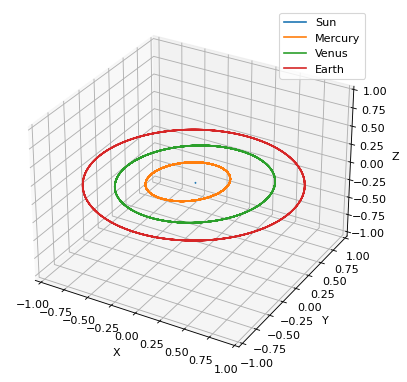

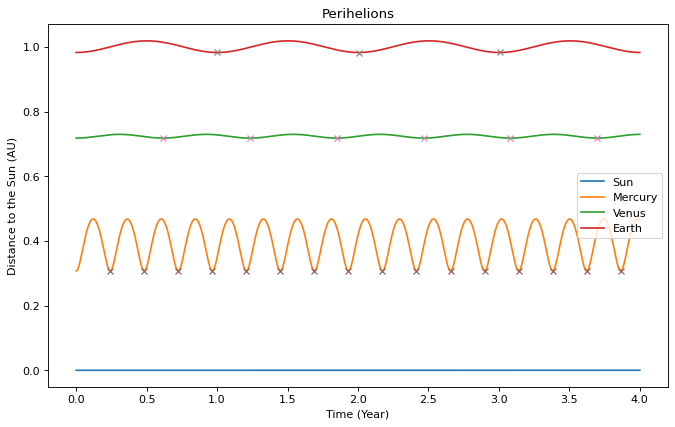

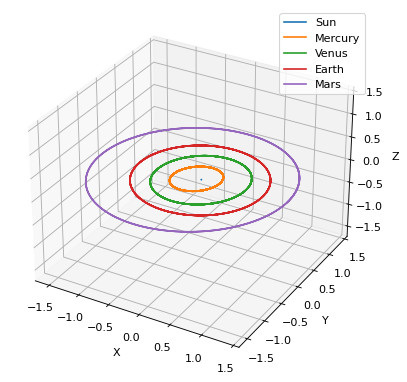

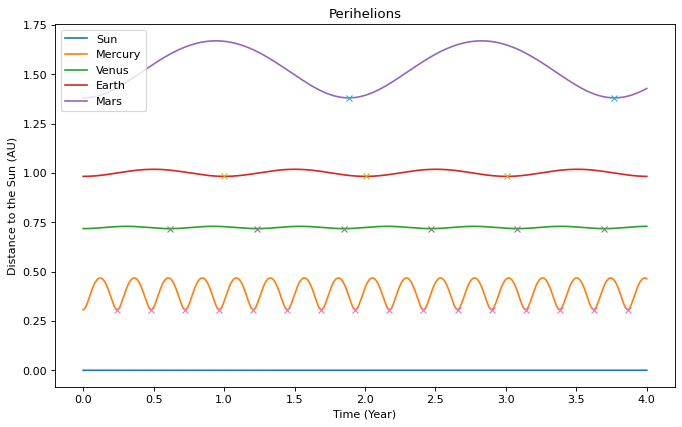

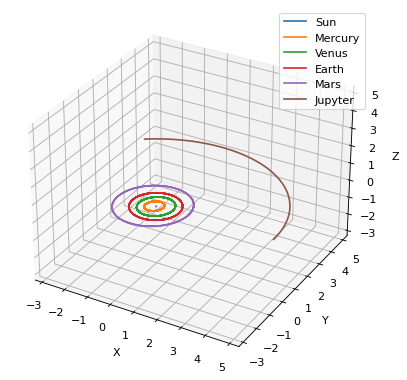

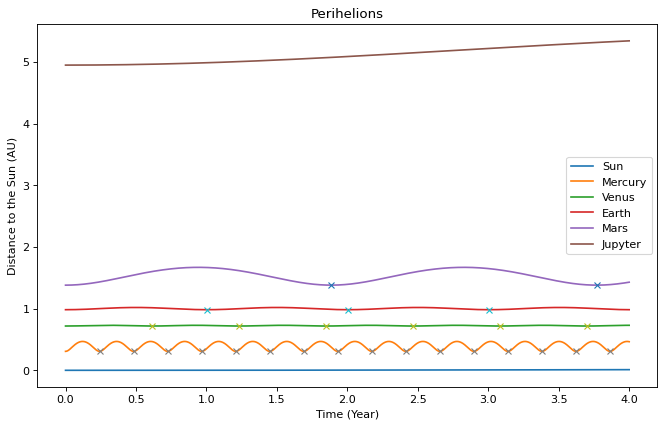

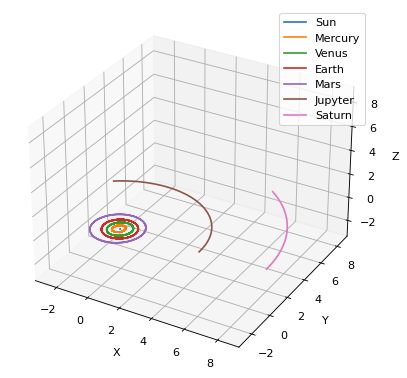

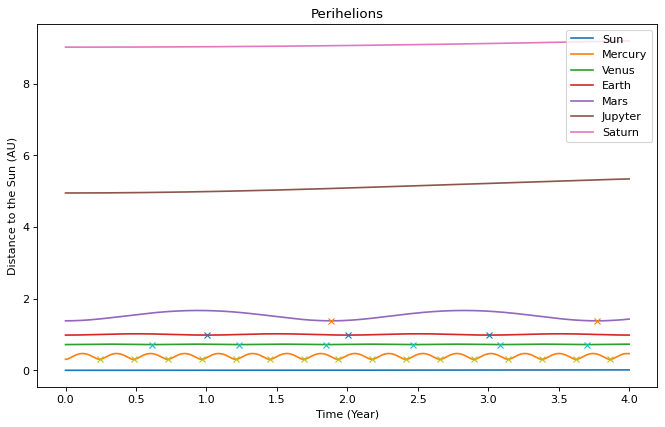

After added Sun the precession is: 4.147808707513265
After added Mercury the precession is: 4.381032837251058
After added Venus the precession is: 4.5879047581233525
After added Earth the precession is: 4.8527813123466395
After added Mars the precession is: 4.7505861793682636


In [17]:
p2res = []
arguments["Include"] = [0, 1]
arguments["DrawInclude"] = [0, 1]
for i in range(2, len(names)): # add one planet at a time
    arguments["Include"].append(i)
    arguments["DrawInclude"].append(i)

    M = 10 ** 7

    t_span = np.array([0, 4]) # 30 years
    ts = np.linspace(t_span[0], t_span[1], M)
    y0 = np.concatenate((init_position.flatten(), init_velocity.flatten()))

    sol2 = solve_ivp(lambda t, state: adapter(t, state, arguments, "Newton"), t_span, y0, method='DOP853', t_eval=ts, atol=atol, rtol=rtol)
    sol2 = get_components(sol2)

    # draw_orbits_anime(sol2, arguments, "Newton-orbits-anime" + '-'.join(list(map(str, arguments["Include"]))))
    draw_orbits(sol2, arguments, "Newton-orbits-" + '-'.join(list(map(str, arguments["Include"]))))
    precessions2 = draw_perihelions(sol2, arguments, False, "Newton-perihelions-" + '-'.join(list(map(str, arguments["Include"]))))
    pre = np.abs(np.sum(np.abs(precessions2[MERCURY])) / len(precessions2[MERCURY]) * rad2as)
    p2res.append(pre)
for i in range(len(p2res)):
    print("After added " + names[i] + " the precession is: " + str(p2res[i]))

In [19]:
ave_precession2 = np.abs(np.sum(np.abs(precessions2[MERCURY])) / len(precessions2[MERCURY]) * rad2as)
print("precession in arcseconds: {:.6}".format(ave_precession2))

precession in arcseconds: 4.75059


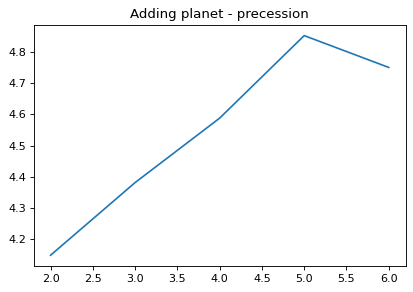

In [20]:
fig = plt.figure(fig_index)
fig_index += 1
plt.plot(np.array(list(range(2, len(names)))), p2res)
plt.title("Adding planet - precession")
plt.show()

In [ ]:
# draw_orbits_anime(sol2, arguments, "Newton-orbits-anime-full")

#### Einstein's Theory

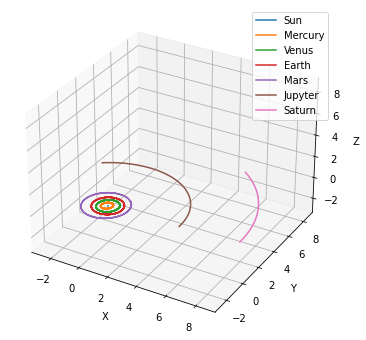

C:\Users\35995\AppData\Local\Temp\ipykernel_31376\1812020812.py:24: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  valley_indexes = np.array(valley_indexes).T
C:\Users\35995\AppData\Local\Temp\ipykernel_31376\1812020812.py:25: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  valley_ys = np.array(valley_ys).T
C:\Users\35995\AppData\Local\Temp\ipykernel_31376\1812020812.py:44: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig(filename + ".png", dpi=200)
C:\Users\35995\AppData\Roaming\Python\Python310\site-pa

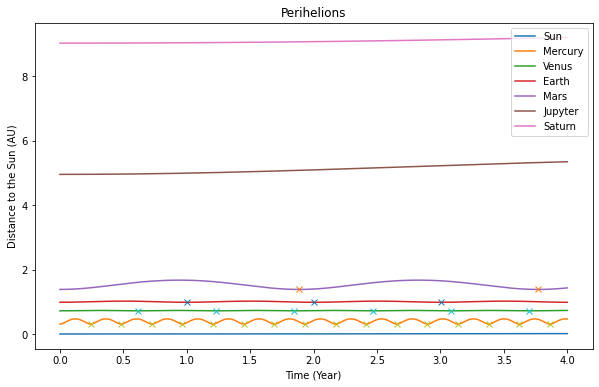

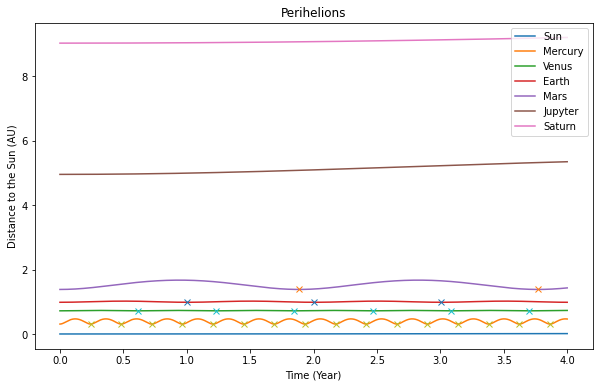

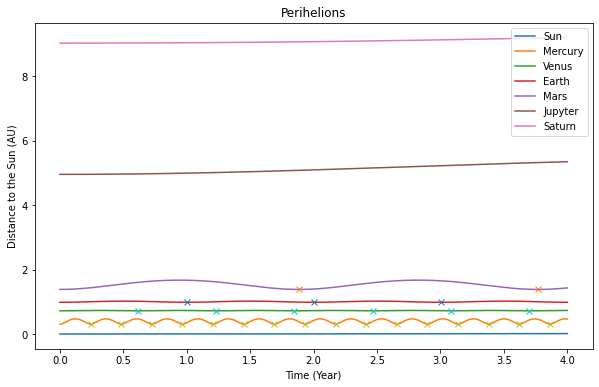

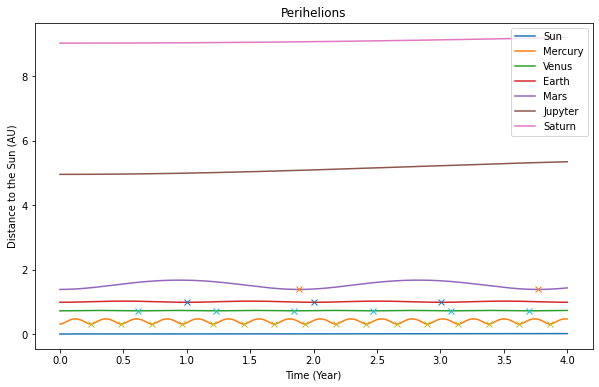

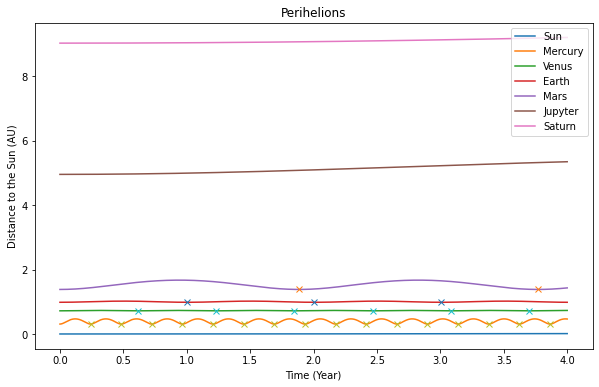

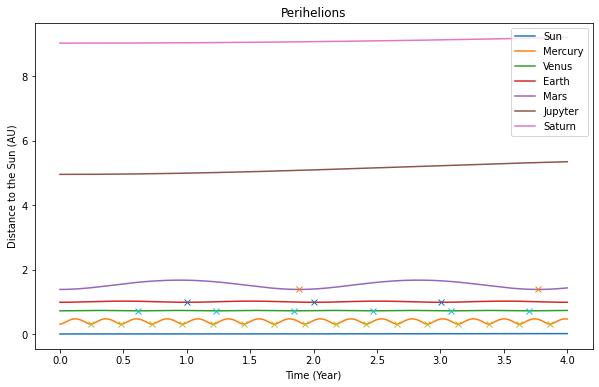

MemoryError: Unable to allocate 6.26 GiB for an array with shape (42, 20000000) and data type float64

In [32]:
ori_alpha = alpha
multiples = np.linspace(100, 20, 17)
alphas = multiples * alpha

arguments["Include"] = [] # empty for 'all'
arguments["DrawInclude"] = []

res = []
for i in range(len(alphas)):
    alpha = alphas[i]

    M = 10 ** 7 * 2

    t_span = np.array([0, 4]) # 30 years
    ts = np.linspace(t_span[0], t_span[1], M)
    y0 = np.concatenate((init_position.flatten(), init_velocity.flatten()))

    psol = solve_ivp(lambda t, state: adapter(t, state, arguments, "Relativity"), t_span, y0, method='DOP853', t_eval=ts, atol=atol, rtol=rtol)
    psol = get_components(psol)

    # draw_orbits_anime(psol, arguments, "Einstein-orbits-anime")
    if i == 0:  
        draw_orbits(psol, arguments, "Rel-orbits-alpha-" + str(multiples[i]))
    pprecessions = draw_perihelions(psol, arguments, False if i else True, "Rel-perihelions-alpha-" + str(multiples[i]))

    ave_precession = np.abs(np.sum(np.abs(pprecessions[MERCURY])) / len(pprecessions[MERCURY]) * rad2as)
    res.append(ave_precession)

alpha = ori_alpha # recover

In [33]:
res

[10.938870918529808,
 10.389199316364293,
 9.862922826052166,
 9.401203579193218,
 9.073671238546801,
 8.815213010520578,
 8.352814663784669]

In [35]:
fits = np.polyfit(multiples[:len(res)], res, 1)

f = lambda x: fits[1] + fits[0] * x

xs = np.linspace(0, 100, 101)
ys = f(xs)

fig = plt.figure(fig_index)
fig.set_size_inches(10, 6)
fig_index += 1
plt.plot(xs, ys)
plt.scatter(multiples, res)
plt.scatter([1], [f(1)])
plt.title("Fitting line of alpha and precessions")
fig.savefig("fit.png", dpi=200)

print("relative coefficient: " + str(np.corrcoef(multiples, res)))
print("precession at exactly alpha: " + str(f(1))) # 1 times a, which is demanded

TypeError: expected x and y to have same length

It's propotional, as we expected.